# Model 1 information

Model 1 included ClosePrice, which is only known after the auction has ended. As a result, it is not a good predictor for new auctions, as it causes data leakage.

As a result, model 2 will drop this predictor from the decision tree, while keeping all other predictors. 

The same data, splitting criteria, and other aspects will be considered to ensure consistency between the models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

In [3]:
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze('columns')
y_test = pd.read_csv('y_test.csv').squeeze('columns')

In [4]:
# Checking training and testing data predictor shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
# Checking available predictors
print("\nPredictors:")
print(X_train.columns.tolist())
# Checking target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Checking X_train head
X_train.head()

Training data: (1183, 36)
Testing data: (789, 36)

Predictors:
['sellerRating', 'ClosePrice', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']

Training target distribution:
Competitive
1    0.540152
0    0.459848
Name: proportion, dtype: float64

Testing target distribution:
Competitive
1    0.541191
0    0.458809
Name: proportion, dtype: float64


,sellerRating,ClosePrice,OpenPrice,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,Category_Collectibles,...,Duration_5,Duration_7,Duration_10,endDay_Sun,endDay_Mon,endDay_Tue,endDay_Wed,endDay_Thu,endDay_Fri,endDay_Sat
0,4390.0,41.49,41.49,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,1155.0,8.99,8.99,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
2,2046.0,7.50,7.50,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
3,1266.0,6.79,6.79,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,1364.0,30.95,30.95,0,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [5]:
y_test.head(5)

0    1
1    1
2    1
3    0
4    1
Name: Competitive, dtype: int64

In [6]:
# Excluding ClosePrice from the data
X_train_model2 = X_train.drop(columns=['ClosePrice'])
X_test_model2 = X_test.drop(columns=['ClosePrice'])

In [7]:
# Verifying the remaining predictors
print("Training data:", X_train_model2.shape)
print("Testing data:", X_test_model2.shape)
print("\nRemaining predictors:")
print(X_train_model2.columns.tolist())

Training data: (1183, 35)
Testing data: (789, 35)

Remaining predictors:
['sellerRating', 'OpenPrice', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10', 'endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']


In [8]:
# Building a new classification tree without ClosePrice
model2 = DecisionTreeClassifier(
    criterion='entropy',
    min_samples_leaf=50,
    random_state=42
)

# Fit the model on the training data
model2.fit(X_train_model2, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sam

In [9]:
# Checking the structure of Model 2
print("Number of terminal nodes:", model2.get_n_leaves())
print("Tree depth:", model2.get_depth())

# Verifying the minimum terminal node size
leaf_mask = model2.tree_.children_left == -1
print("Smallest terminal node:", model2.tree_.n_node_samples[leaf_mask].min())

Number of terminal nodes: 17
Tree depth: 6
Smallest terminal node: 50


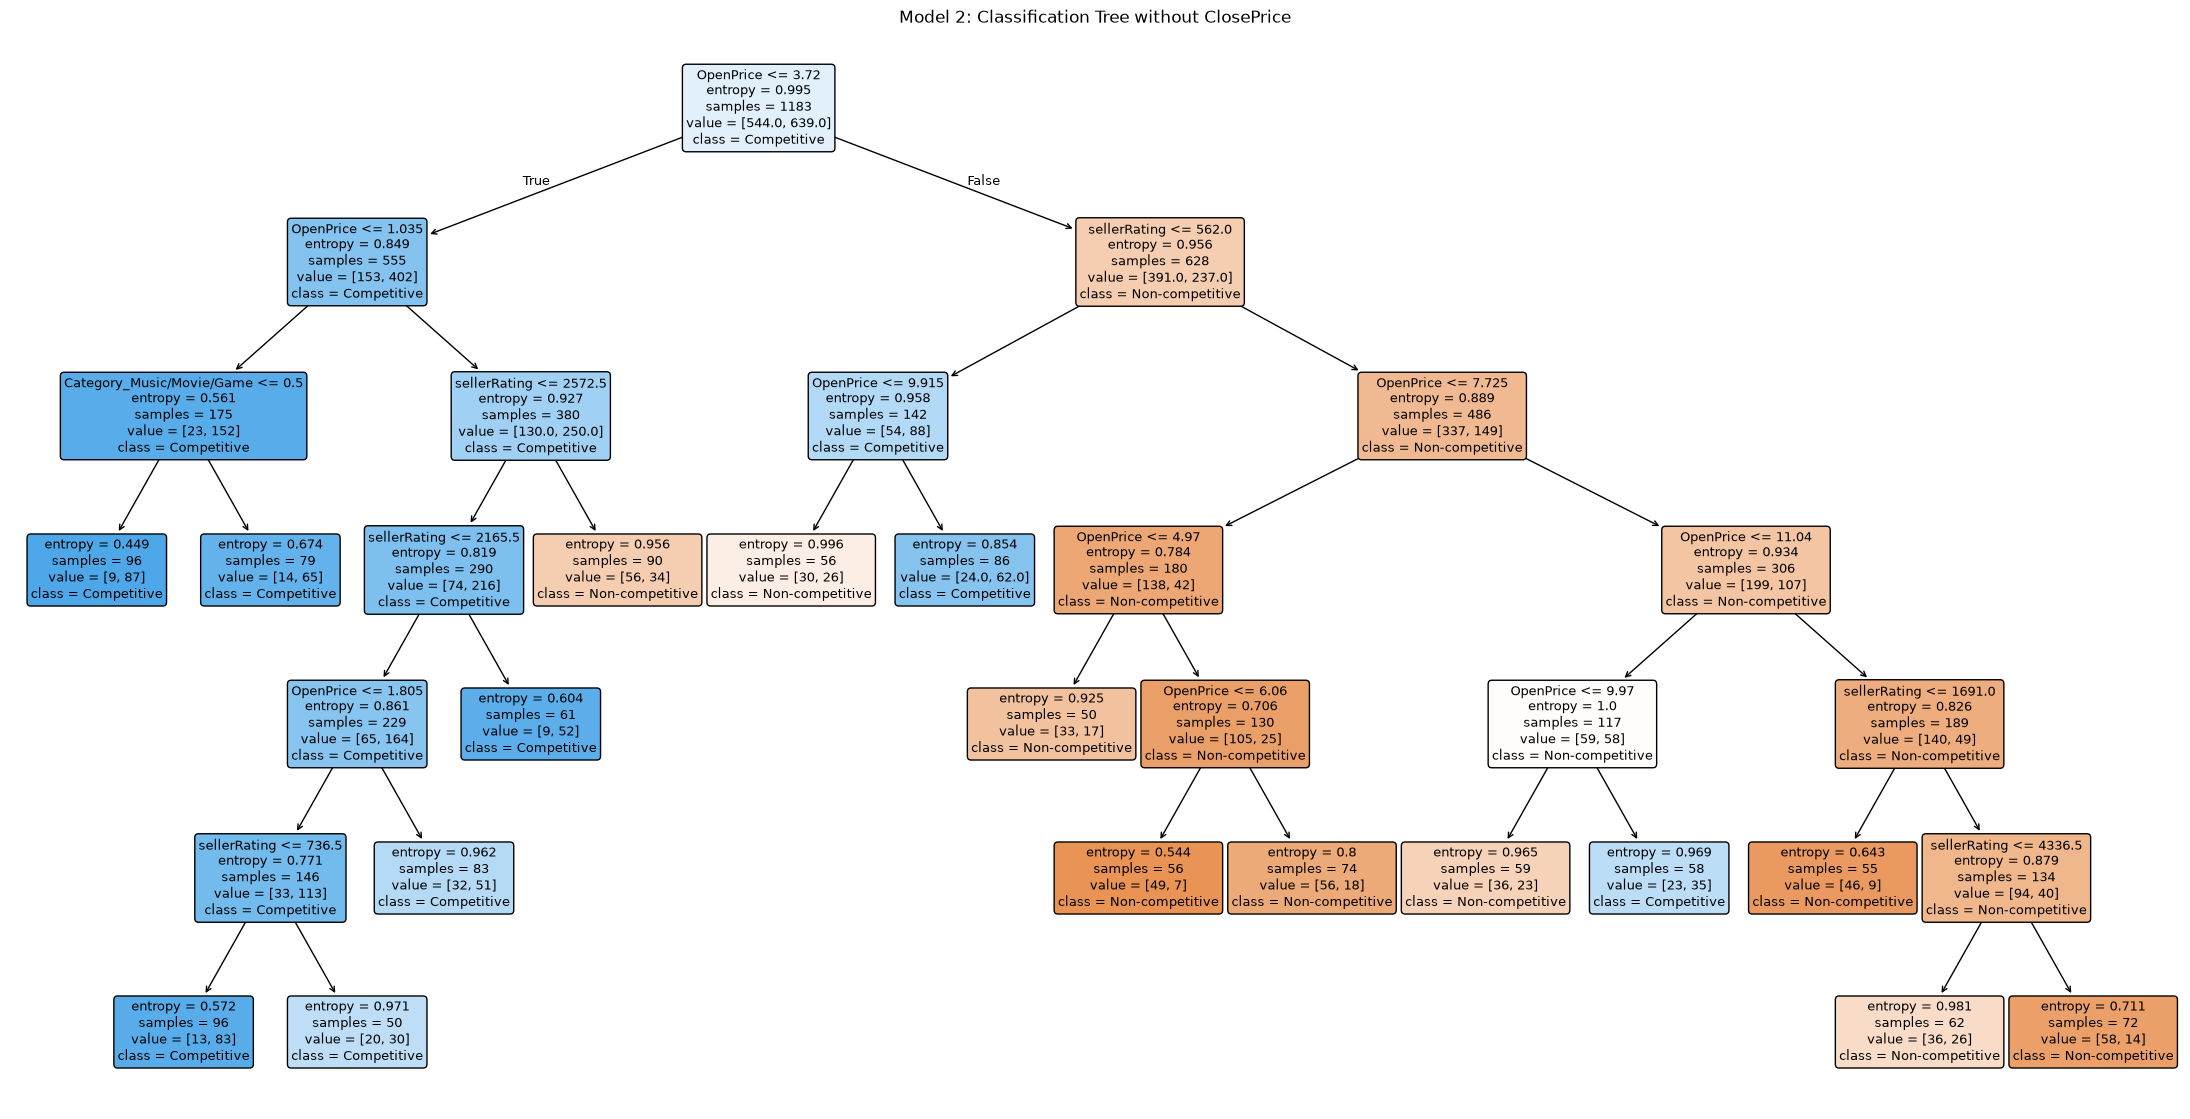

In [10]:
# Visualizing Model 2 Tree
plt.figure(figsize=(28, 14))

plot_tree(
    model2,
    feature_names=X_train_model2.columns,
    class_names=['Non-competitive', 'Competitive'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Model 2: Classification Tree without ClosePrice')
plt.show()

In [12]:
# Extracting decision rules from Model 2
rules_model2 = export_text(
    model2,
    feature_names=list(X_train_model2.columns),
    decimals=3
)

print(rules_model2)

|--- OpenPrice <= 3.720
|   |--- OpenPrice <= 1.035
|   |   |--- Category_Music/Movie/Game <= 0.500
|   |   |   |--- class: 1
|   |   |--- Category_Music/Movie/Game >  0.500
|   |   |   |--- class: 1
|   |--- OpenPrice >  1.035
|   |   |--- sellerRating <= 2572.500
|   |   |   |--- sellerRating <= 2165.500
|   |   |   |   |--- OpenPrice <= 1.805
|   |   |   |   |   |--- sellerRating <= 736.500
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- sellerRating >  736.500
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- OpenPrice >  1.805
|   |   |   |   |   |--- class: 1
|   |   |   |--- sellerRating >  2165.500
|   |   |   |   |--- class: 1
|   |   |--- sellerRating >  2572.500
|   |   |   |--- class: 0
|--- OpenPrice >  3.720
|   |--- sellerRating <= 562.000
|   |   |--- OpenPrice <= 9.915
|   |   |   |--- class: 0
|   |   |--- OpenPrice >  9.915
|   |   |   |--- class: 1
|   |--- sellerRating >  562.000
|   |   |--- OpenPrice <= 7.725
|   |   |   |--- OpenPrice <= 

In [13]:
# Calculating feature importance
importance_model2 = pd.DataFrame({
    'Feature': X_train_model2.columns,
    'Importance': model2.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_model2.head(3)

,Feature,Importance
1,OpenPrice,0.662484
0,sellerRating,0.329886
15,Category_Music/Movie/Game,0.007630


# Model 2 information

It can now be appreciated that ClosePrice is not used in any of the decisions of the new decision tree. Once again, the criterion used for splitting has been entropy, and we have set a minimum node size of 50 and the random state 42.

In this new tree, the predictors used by the tree for decisions have been `OpenPrice`, `Category_Music/Movie/Game`, and `sellerRating`, where `OpenPrice` seems to be the main driver of auction competitiveness, and `SellerRating` looks to provide additional information within different price ranges.

In this new tree, none of the terminal nodes show an entropy value of 0, that is, no terminal node is complletely pure; however, some of the key decision rules are summarized below:

| Predictor | Model 1 feature importance | Model 2 feature importance |
|---|---|---:|
| `ClosePrice` | 54.14% | Excluded |
| `OpenPrice` | 40.57% | 66.25% |
| `SellerRating` | 5.30% | 32.99% |
| `Category` | 0% | 0.76% |
| `Other predictors` | 0% | 0% |

As can be seen from the comparison, Model 2 now places a substantially higher emphasis on `OpenPrice` compared to Model 1, as well as on `SellerRating`.

### Patterns in Model 2

1- Auctions with lower opening prices are more likely to receive multiple bids in the training data. This makes intutive sense, as lower opening prices reduce the initial financial barrier to participation.

    1.1- OpenPrice in the first split divides the 1183 observations according to whether the opening price is above or below 3.720. Based on this split, the competitive rate decreases from 72.4% (402/555 auctions are competitive) to 37.7% (237/628 auctions are competitive) when moving from the lower opening price group to the higher opening price group.

2- Setting a very low opening price is associated with high auction competitiveness across item categories, however, the strength of this relationship varies slightly by category.

    2.1- For auctions with a opening price of 1.035 or less, the competitive rate increases further (i.e., 152/175=86.9%). Within this group, the model differentiates items belonging to the Music/Movie/Game category and all other categories. As a result, it can be appreciated that 82.3% of the auctions within the selected category are competitive, compared to the 90.6% rate of the other categories.

### Unexpected finding

1- The relationship between seller rating and auction competitiveness is nonlinear and depends on the opening price. 

    1.1- For auctions with an opening price between 1.035 and 3.720, seller rating becomes an important distinguishing factor. This is because sellers with a rating smaller or equal to 2572.5 show a competitive rate of 74.5%, compared to the 37.8% of the items with a seller rating bigger than 2572.5, and because of this, the predicted class changes from Competitive to Non-competitive. However, intuition says otherwise: We expect sellers with higher ratings to attract greater bidding activity because of their reputations. However, within the specified opening price, sellers with ratings above 2572.5 experience lower competitiveness.

    1.2- Moreover, within the opening price of 1.035 to 1.805, sellers with a rating smaller or equal to 736.5 show a competitive rate of 86.5%, compared to the 60.0% rate of the sellers with a rating between 736.5 and 2165.5. Once again, this shows that higher seller ratings are not consistently associated with greater competitiveness. However, the relationship is not strictly decreasing. Sellers with ratings between 2165.5 and 2572.5, within the broader opening price range of 1.035 to 3.720, achieve a competitive rate of 85.2%.

2- Lowering the opening price does not necessarily increase competitiveness.

    2.1- When the opening price exceeds 3.720, seller rating is used to distinguish between two groups: seller rating smaller or equal to 562, or greater. These show competitive rates of 62.0% and 30.7%, respectively, showing that sellers with lower ratings have a higher observed comppetitive rate within this price range. However, among the sellers with a rating of 562 or less, items with an opening price between 3.720 and 9.915 (included), show a competitive rate of 46.4%, compared to the 72.1% rate of the items with an opening price greater than 9.915. This shows that, contrary to the general relationship between opening price and competitiveness, higher opening prices are associated with greater competitiveness within this particular seller group.

### Decision rules for Model 2

| Opening price | Seller rating | Competitive rate | Prediction |
|---|---|---|---:|
| ≤ 1.035 | Any | 86.9% | Competitive |
| 1.035-3.720 | ≤ 2572.5 | 74.5% | Competitive |
|  | > 2572.5 | 37.8% | Non-competitive |
| 3.720-9.915 | ≤ 562 | 46.4% | Non-competitive |
| >9.915 | ≤ 562 | 72.1% | Competitive |
| 3.720-9.970 | > 562 | 27.2% | Non-competitive |
| 9.970-11.040 | > 562 | 60.3% | Competitive | 
| > 11.040 | > 562 | 25.9% | Non-competitive |


In [14]:
# Identify the terminal node of each training observation
leaf_ids_model2 = model2.apply(X_train_model2)

# Extract decision paths
paths_model2 = model2.decision_path(X_train_model2)

rules_summary_model2 = []

for leaf_id in np.unique(leaf_ids_model2):

    mask = leaf_ids_model2 == leaf_id
    sample_id = np.where(mask)[0][0]
    node_ids = paths_model2[sample_id].indices

    conditions = []

    for node_id in node_ids:

        if node_id == leaf_id:
            continue

        feature = X_train_model2.columns[
            model2.tree_.feature[node_id]
        ]

        threshold = model2.tree_.threshold[node_id]
        value = X_train_model2.iloc[sample_id][feature]

        operator = "<=" if value <= threshold else ">"

        conditions.append(
            f"{feature} {operator} {threshold:.3f}"
        )

    rules_summary_model2.append({
        'Leaf': leaf_id,
        'Decision Rule': ' AND '.join(conditions),
        'Observations': mask.sum(),
        'Predicted Class': model2.predict(
            X_train_model2.iloc[[sample_id]]
        )[0],
        'Competitive Rate (%)': (y_train[mask] == 1).mean() * 100
    })

# Create the decision rules DataFrame
rules_table_model2 = pd.DataFrame(rules_summary_model2)

rules_table_model2 = rules_table_model2.sort_values(
    'Competitive Rate (%)',
    ascending=False
).reset_index(drop=True)

pd.set_option('display.max_colwidth', None)

display(rules_table_model2.round(2))

,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
0,3,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game <= 0.500,96,1,90.62
1,9,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating <= 736.500,96,1,86.46
2,12,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating > 2165.500,61,1,85.25
3,4,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game > 0.500,79,1,82.28
4,17,OpenPrice > 3.720 AND sellerRating <= 562.000 AND OpenPrice > 9.915,86,1,72.09
5,11,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice > 1.805,83,1,61.45
6,27,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice <= 11.040 AND OpenPrice > 9.970,58,1,60.34
7,10,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating > 736.500,50,1,60.00
8,16,OpenPrice > 3.720 AND sellerRating <= 562.000 AND OpenPrice <= 9.915,56,0,46.43
9,31,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating > 1691.000 AND sellerRating <= 4336.500,62,0,41.94


In [15]:
# The four most competitive auction profiles
most_competitive = rules_table_model2.nlargest(
    4, 'Competitive Rate (%)'
).copy()
# The four least competitive auction profiles
least_competitive = rules_table_model2.nsmallest(
    4, 'Competitive Rate (%)'
).copy()

display(most_competitive)
display(least_competitive)

,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
0,3,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game <= 0.500,96,1,90.625000
1,9,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating <= 2165.500 AND OpenPrice <= 1.805 AND sellerRating <= 736.500,96,1,86.458333
2,12,OpenPrice <= 3.720 AND OpenPrice > 1.035 AND sellerRating <= 2572.500 AND sellerRating > 2165.500,61,1,85.245902
3,4,OpenPrice <= 3.720 AND OpenPrice <= 1.035 AND Category_Music/Movie/Game > 0.500,79,1,82.278481


,Leaf,Decision Rule,Observations,Predicted Class,Competitive Rate (%)
16,22,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice <= 7.725 AND OpenPrice > 4.970 AND OpenPrice <= 6.060,56,0,12.500000
15,29,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating <= 1691.000,55,0,16.363636
14,32,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice > 7.725 AND OpenPrice > 11.040 AND sellerRating > 1691.000 AND sellerRating > 4336.500,72,0,19.444444
13,23,OpenPrice > 3.720 AND sellerRating > 562.000 AND OpenPrice <= 7.725 AND OpenPrice > 4.970 AND OpenPrice > 6.060,74,0,24.324324


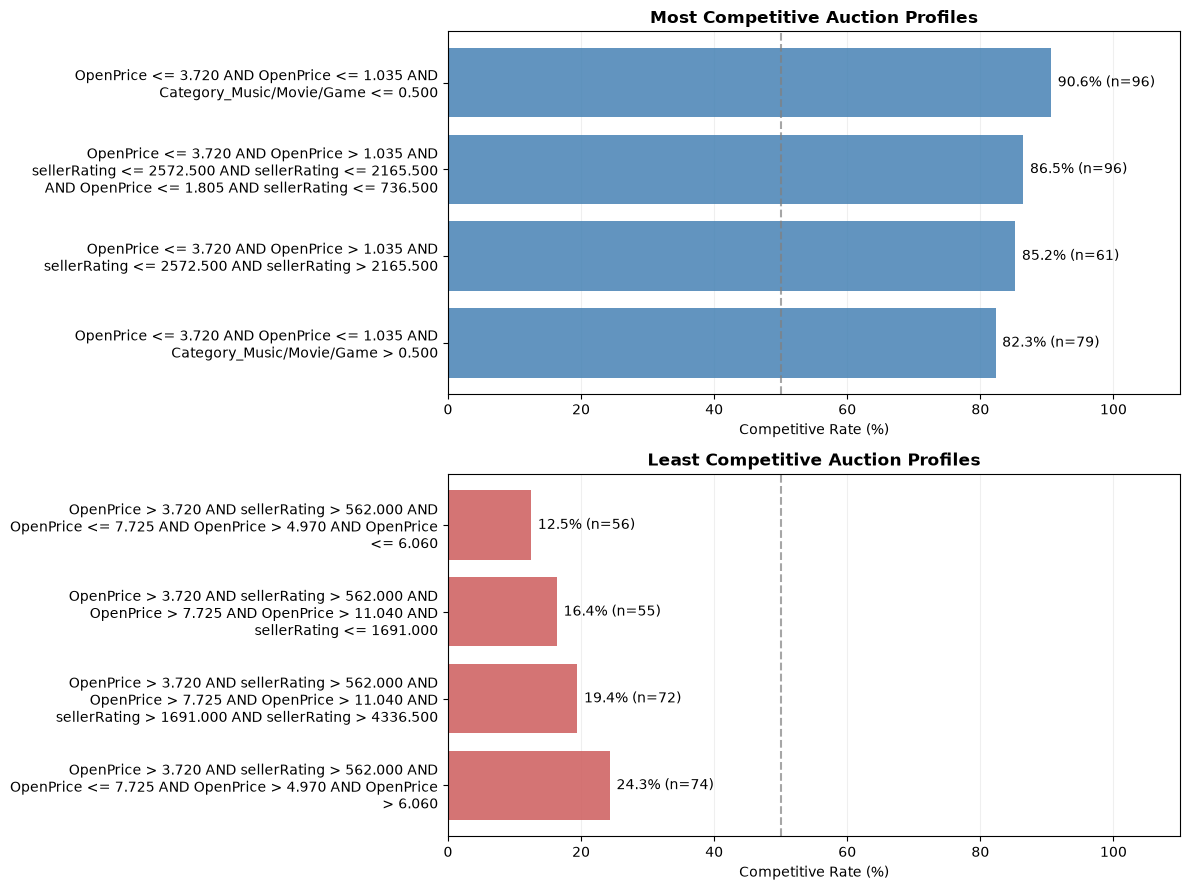

In [16]:
import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for ax, data, color, title in [
    (axes[0], most_competitive, 'steelblue',
     'Most Competitive Auction Profiles'),
    (axes[1], least_competitive, 'indianred',
     'Least Competitive Auction Profiles')
]:

    labels = [
        textwrap.fill(rule, width=55)
        for rule in data['Decision Rule']
    ]

    bars = ax.barh(
        labels,
        data['Competitive Rate (%)'],
        color=color,
        alpha=0.85
    )

    for bar, rate, n in zip(
        bars,
        data['Competitive Rate (%)'],
        data['Observations']
    ):
        ax.text(
            rate + 1,
            bar.get_y() + bar.get_height() / 2,
            f'{rate:.1f}% (n={n})',
            va='center',
            fontsize=10
        )

    ax.axvline(50, color='gray', linestyle='--', alpha=0.7)

    ax.set_xlim(0, 110)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlabel('Competitive Rate (%)')
    ax.set_title(title, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    'Model2_auction_profiles.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Decision rules

In [17]:
# Extracting all internal decision nodes
splits_model2 = []

for node_id in range(model2.tree_.node_count):

    feature_id = model2.tree_.feature[node_id]

    # Exclude terminal nodes
    if feature_id >= 0:

        splits_model2.append({
            'Node': node_id,
            'Predictor': X_train_model2.columns[feature_id],
            'Threshold': model2.tree_.threshold[node_id],
            'Observations': model2.tree_.n_node_samples[node_id]
        })

splits_table_model2 = pd.DataFrame(splits_model2)

display(splits_table_model2.round(3))

,Node,Predictor,Threshold,Observations
0,0,OpenPrice,3.720,1183
1,1,OpenPrice,1.035,555
2,2,Category_Music/Movie/Game,0.500,175
3,5,sellerRating,2572.500,380
4,6,sellerRating,2165.500,290
5,7,OpenPrice,1.805,229
6,8,sellerRating,736.500,146
7,14,sellerRating,562.000,628
8,15,OpenPrice,9.915,142
9,18,OpenPrice,7.725,486


In [18]:
quantitative_splits_model2 = splits_table_model2[
    splits_table_model2['Predictor'].isin(
        ['OpenPrice', 'sellerRating']
    )
]

display(quantitative_splits_model2.round(3))

,Node,Predictor,Threshold,Observations
0,0,OpenPrice,3.720,1183
1,1,OpenPrice,1.035,555
3,5,sellerRating,2572.500,380
4,6,sellerRating,2165.500,290
5,7,OpenPrice,1.805,229
6,8,sellerRating,736.500,146
7,14,sellerRating,562.000,628
8,15,OpenPrice,9.915,142
9,18,OpenPrice,7.725,486
10,19,OpenPrice,4.970,180


# Visualization and Model Evaluation

## Scatter plot with splitting boundaries

The two most important quantitative predictors in Model 2 are `OpenPrice` and `sellerRating`, accounting for 66.25% and 32.99% of the total feature importance, respectively.

The first scatter plot displays all 1,972 auction observations from the training and test datasets, with `OpenPrice` on the horizontal axis and `sellerRating` on the vertical axis.

Red points represent non-competitive auctions, while blue points represent competitive auctions. The black dashed lines represent the quantitative splitting boundaries obtained from Model 2, which was fitted using only the training dataset.

Since several observations have substantially higher opening prices and seller ratings, the splitting boundaries are difficult to distinguish in the original scatter plot.

Therefore, a second scatter plot provides a zoomed-in view of opening prices between 0 and 12 and seller ratings between 0 and 5,000. This region contains all 15 quantitative splitting thresholds of Model 2.

Both plots use the original predictor values without transformation. The zoomed-in view only changes the displayed axis ranges and does not modify the dataset or the fitted decision tree.

Since `Category_Music/Movie/Game` is a categorical predictor, its split cannot be directly represented on these two-dimensional scatter plots.

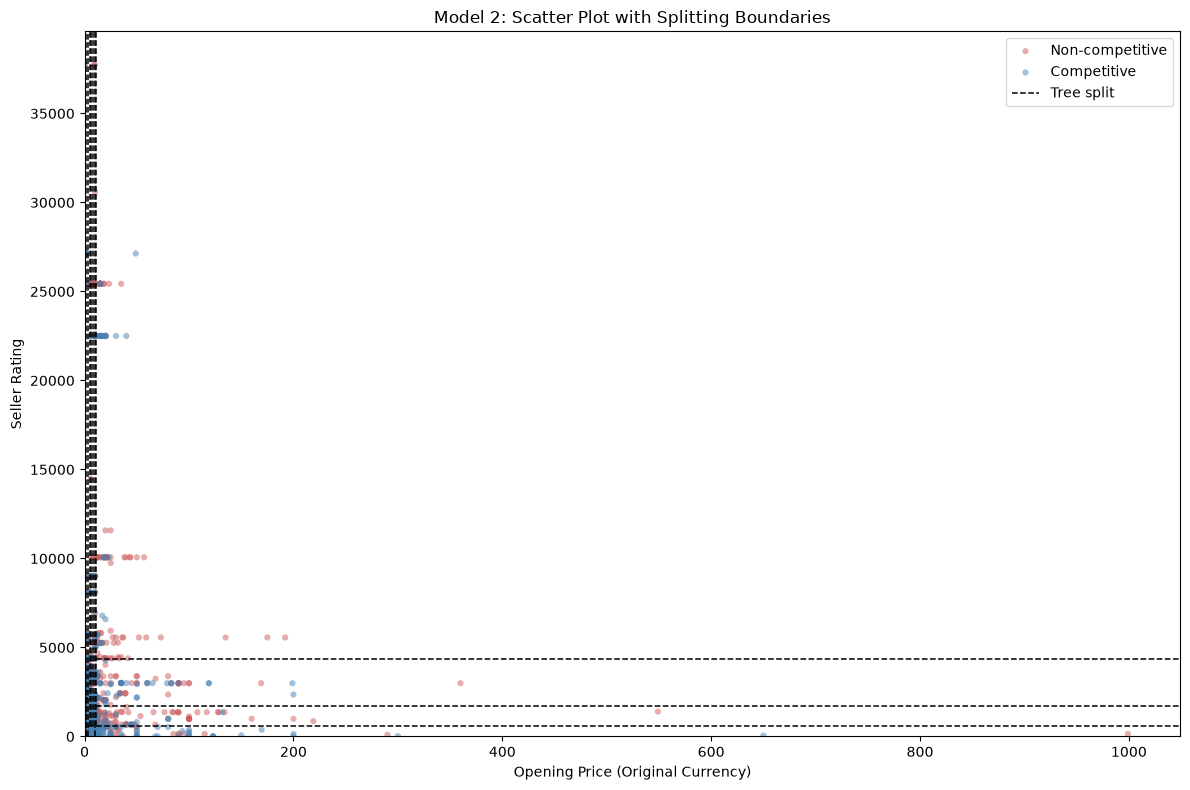

Total auction observations: 1972


,Node,Predictor,Threshold
0,0,OpenPrice,3.720
1,1,OpenPrice,1.035
2,5,sellerRating,2572.500
3,6,sellerRating,2165.500
4,7,OpenPrice,1.805
5,8,sellerRating,736.500
6,14,sellerRating,562.000
7,15,OpenPrice,9.915
8,18,OpenPrice,7.725
9,19,OpenPrice,4.970


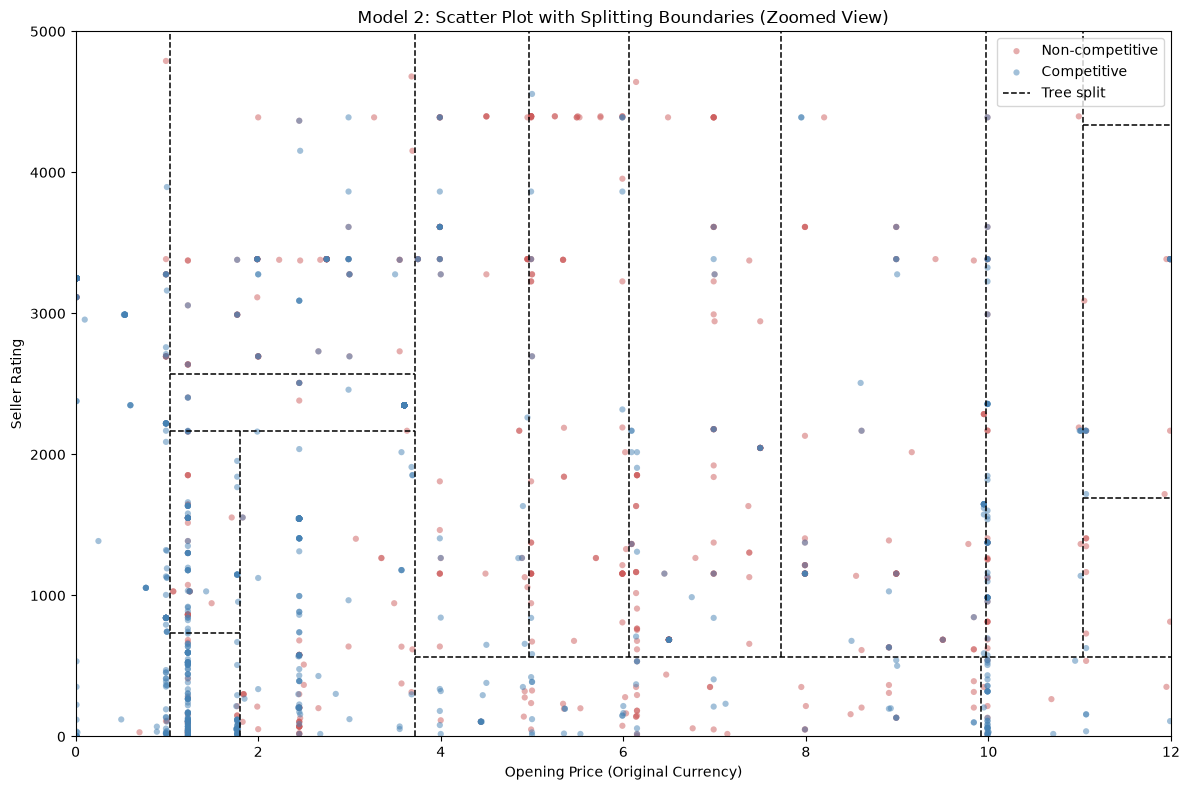

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Combine training and test observations for visualization
X_plot4 = pd.concat(
    [X_train_model2, X_test_model2],
    ignore_index=True
)

y_plot4 = np.concatenate([
    np.asarray(y_train).ravel(),
    np.asarray(y_test).ravel()
])

# Select the two most important quantitative predictors
features4 = list(X_train_model2.columns)
x4 = 'OpenPrice'
y4 = 'sellerRating'

# Obtain the fitted decision tree
tree4 = model2.tree_

# Create the scatter plot
fig, ax = plt.subplots(figsize=(12, 8))

for cls, color, label in [
    (0, 'indianred', 'Non-competitive'),
    (1, 'steelblue', 'Competitive')
]:
    mask = y_plot4 == cls

    ax.scatter(
        X_plot4.loc[mask, x4],
        X_plot4.loc[mask, y4],
        c=color,
        label=label,
        s=20,
        alpha=0.5,
        edgecolors='none'
    )

# Set the axis limits using the original predictor values
xmin4 = min(0, X_plot4[x4].min())
xmax4 = X_plot4[x4].max() * 1.05

ymin4 = min(0, X_plot4[y4].min())
ymax4 = X_plot4[y4].max() * 1.05

ax.set_xlim(xmin4, xmax4)
ax.set_ylim(ymin4, ymax4)

# Store the quantitative splitting boundaries
segments4 = set()

# Traverse the decision tree to obtain splitting boundaries
def draw_splits4(node, xmin, xmax, ymin, ymax):

    # Stop when a terminal node is reached
    if tree4.children_left[node] == -1:
        return

    feature = features4[tree4.feature[node]]
    threshold = tree4.threshold[node]

    left = tree4.children_left[node]
    right = tree4.children_right[node]

    # Split based on opening price
    if feature == x4:

        segments4.add(
            ('vertical', threshold, ymin, ymax)
        )

        draw_splits4(
            left, xmin, threshold, ymin, ymax
        )

        draw_splits4(
            right, threshold, xmax, ymin, ymax
        )

    # Split based on seller rating
    elif feature == y4:

        segments4.add(
            ('horizontal', threshold, xmin, xmax)
        )

        draw_splits4(
            left, xmin, xmax, ymin, threshold
        )

        draw_splits4(
            right, xmin, xmax, threshold, ymax
        )

    # Categorical splits cannot be displayed on these axes
    else:

        draw_splits4(
            left, xmin, xmax, ymin, ymax
        )

        draw_splits4(
            right, xmin, xmax, ymin, ymax
        )

# Start from the root node
draw_splits4(0, xmin4, xmax4, ymin4, ymax4)

# Draw the splitting boundaries
for i, (direction, threshold, low, high) in enumerate(
    sorted(segments4)
):

    label = 'Tree split' if i == 0 else None

    if direction == 'vertical':

        ax.vlines(
            threshold, low, high,
            colors='black',
            linestyles='--',
            linewidth=1.1,
            label=label
        )

    else:

        ax.hlines(
            threshold, low, high,
            colors='black',
            linestyles='--',
            linewidth=1.1,
            label=label
        )

# Add labels and title
ax.set_xlabel('Opening Price (Original Currency)')
ax.set_ylabel('Seller Rating')
ax.set_title('Model 2: Scatter Plot with Splitting Boundaries')

ax.legend(loc='upper right')

fig.tight_layout()

fig.savefig(
    'Person4_scatter.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display the number of auction observations
print(f'Total auction observations: {len(X_plot4)}')

# Display the quantitative splitting thresholds
thresholds4 = pd.DataFrame([
    {
        'Node': i,
        'Predictor': features4[f],
        'Threshold': tree4.threshold[i]
    }
    for i, f in enumerate(tree4.feature)
    if f >= 0 and features4[f] in [x4, y4]
])

display(thresholds4.round(3))

# Zoom in on the region containing the splitting thresholds
ax.set_xlim(0, 12)
ax.set_ylim(0, 5000)

ax.set_title(
    'Model 2: Scatter Plot with Splitting Boundaries (Zoomed View)'
)

fig.savefig(
    'Person4_scatter_zoomed.png',
    dpi=300,
    bbox_inches='tight'
)

display(fig)

## Interpretation of splitting boundaries

As can be seen from the scatter plots and the splitting thresholds table, Model 2 uses nine splitting thresholds for `OpenPrice` and six splitting thresholds for `sellerRating`.

| Predictor | Splitting thresholds |
|---|---|
| `OpenPrice` | 1.035, 1.805, 3.720, 4.970, 6.060, 7.725, 9.915, 9.970, 11.040 |
| `sellerRating` | 562, 736.5, 1691, 2165.5, 2572.5, 4336.5 |

These splitting thresholds are selected based on information gain, which measures the reduction in entropy resulting from a split.

### Reasonableness of the splitting boundaries

The first split occurs at an opening price of 3.720, indicating that `OpenPrice` is the main predictor used to distinguish between competitive and non-competitive auctions.

As can be observed from the zoomed-in scatter plot, competitive auctions appear more frequently in several regions with relatively low opening prices, particularly around opening prices of 1 and 2.

This splitting pattern appears reasonable from a business perspective, as lower opening prices may reduce the initial financial barrier to participation and encourage more buyers to place bids.

However, competitive auctions are also observed at higher opening prices, indicating that opening price alone cannot completely determine auction competitiveness.

The horizontal splitting boundaries show that the effect of `sellerRating` depends on the opening price range.

For example, within the opening price range of 1.035 to 3.720, the decision tree uses seller rating thresholds of 2165.5 and 2572.5 to further partition the observations.

For opening prices above 3.720, the model introduces a seller rating threshold of 562, followed by additional splits in different price regions.

These conditional splitting rules demonstrate how the decision tree uses combinations of predictors to improve the homogeneity of the resulting child nodes.

### Separation of competitive and non-competitive auctions

In the original scatter plot, a large proportion of the observations are concentrated in the lower-left region. Several observations with substantially higher opening prices and seller ratings extend the range of the axes, making the individual splitting boundaries difficult to distinguish.

The zoomed-in scatter plot provides a clearer representation of the quantitative splitting boundaries and the distribution of the two classes.

Although some regions contain visibly more competitive auctions than non-competitive auctions, red and blue points remain present within many of the same regions.

Therefore, the splitting boundaries provide partial separation between the two classes but do not achieve complete separation.

This observation is consistent with the non-zero entropy values of the terminal nodes in Model 2, indicating that the resulting groups are not completely homogeneous.

Furthermore, the two-dimensional scatter plots cannot represent the categorical split involving `Category_Music/Movie/Game`. Consequently, the plots do not capture all the decision rules of Model 2.

Another limitation is that opening prices are expressed in their original currencies, meaning that identical numerical opening prices may represent different monetary values across auctions.

Overall, the splitting boundaries appear reasonable with respect to the meaning of the two predictors. However, the separation between competitive and non-competitive auctions is imperfect.

The predictive performance of Model 2 is therefore further examined using the contingency table and classification evaluation measures.

## Model evaluation

To evaluate the predictive performance of Model 2, predictions are generated using the test dataset, which was not used to train the decision tree.

A contingency table is constructed to compare the actual classifications with the predicted classifications.

Competitive auctions are defined as the positive class (1), while non-competitive auctions are defined as the negative class (0).

The four classification outcomes are:

- **True Negative (TN):** A non-competitive auction is correctly classified as non-competitive.
- **False Positive (FP):** A non-competitive auction is incorrectly classified as competitive.
- **False Negative (FN):** A competitive auction is incorrectly classified as non-competitive.
- **True Positive (TP):** A competitive auction is correctly classified as competitive.

The following evaluation measures are calculated based on the contingency table.

| Evaluation Measure | Formula |
|---|---|
| Accuracy | (TN + TP) / N |
| Overall Error Rate | (FP + FN) / N |
| Sensitivity | TP / (TP + FN) |
| False Negative Rate | FN / (TP + FN) |
| Specificity | TN / (TN + FP) |
| False Positive Rate | FP / (TN + FP) |
| Proportion of True Positives | TP / (TP + FP) |
| Proportion of False Positives | FP / (TP + FP) |
| Proportion of True Negatives | TN / (TN + FN) |
| Proportion of False Negatives | FN / (TN + FN) |

Here, N represents the total number of observations in the test dataset.

Contingency Table:


,Predicted Non-competitive,Predicted Competitive,Total
Actual Non-competitive,269,93,362
Actual Competitive,119,308,427
Total,388,401,789


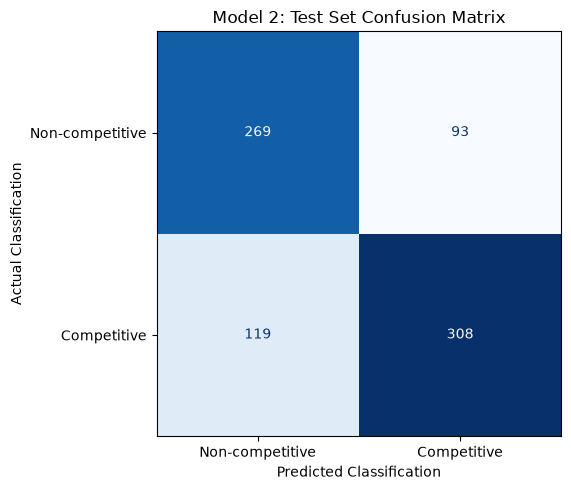

Classification Evaluation Measures:
           Evaluation Measure Model 2
                     Accuracy  73.13%
           Overall Error Rate  26.87%
                  Sensitivity  72.13%
          False Negative Rate  27.87%
                  Specificity  74.31%
          False Positive Rate  25.69%
 Proportion of True Positives  76.81%
Proportion of False Positives  23.19%
 Proportion of True Negatives  69.33%
Proportion of False Negatives  30.67%
Total test observations: 789


In [20]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Generate predictions using the test dataset
person4_pred = model2.predict(X_test_model2)

# Construct the contingency table
cm4 = confusion_matrix(
    y_test,
    person4_pred,
    labels=[0, 1]
)

# Obtain the four classification outcomes
tn4, fp4, fn4, tp4 = cm4.ravel()

# Display the contingency table
classification_table4 = pd.DataFrame(
    cm4,
    index=[
        'Actual Non-competitive',
        'Actual Competitive'
    ],
    columns=[
        'Predicted Non-competitive',
        'Predicted Competitive'
    ]
)

# Calculate row and column totals
classification_table4['Total'] = (
    classification_table4.sum(axis=1)
)

classification_table4.loc['Total'] = (
    classification_table4.sum(axis=0)
)

print('Contingency Table:')

display(classification_table4)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm4,
    display_labels=[
        'Non-competitive',
        'Competitive'
    ]
).plot(
    ax=ax,
    cmap='Blues',
    colorbar=False
)

ax.set_title('Model 2: Test Set Confusion Matrix')
ax.set_xlabel('Predicted Classification')
ax.set_ylabel('Actual Classification')

fig.tight_layout()

fig.savefig(
    'Person4_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Total number of test observations
N4 = tn4 + fp4 + fn4 + tp4

# Accuracy and overall error rate
accuracy4 = (tn4 + tp4) / N4
error_rate4 = (fp4 + fn4) / N4

# Sensitivity and false negative rate
sensitivity4 = tp4 / (tp4 + fn4)
fnr4 = fn4 / (tp4 + fn4)

# Specificity and false positive rate
specificity4 = tn4 / (tn4 + fp4)
fpr4 = fp4 / (tn4 + fp4)

# Proportions of true and false positives
ptp4 = tp4 / (tp4 + fp4)
pfp4 = fp4 / (tp4 + fp4)

# Proportions of true and false negatives
ptn4 = tn4 / (tn4 + fn4)
pfn4 = fn4 / (tn4 + fn4)

# Summarize the evaluation measures
evaluation_table4 = pd.DataFrame({
    'Evaluation Measure': [
        'Accuracy',
        'Overall Error Rate',
        'Sensitivity',
        'False Negative Rate',
        'Specificity',
        'False Positive Rate',
        'Proportion of True Positives',
        'Proportion of False Positives',
        'Proportion of True Negatives',
        'Proportion of False Negatives'
    ],
    'Model 2': [
        accuracy4,
        error_rate4,
        sensitivity4,
        fnr4,
        specificity4,
        fpr4,
        ptp4,
        pfp4,
        ptn4,
        pfn4
    ]
})

# Display the evaluation table
print('Classification Evaluation Measures:')

evaluation_display4 = evaluation_table4.copy()

evaluation_display4['Model 2'] = (
    evaluation_display4['Model 2'].map('{:.2%}'.format)
)

print(evaluation_display4.to_string(index=False))

# Display the total number of test observations
print(f'Total test observations: {N4}')

## Predictive performance of Model 2

As can be seen from the contingency table and confusion matrix, Model 2 correctly classifies 577 out of 789 auction observations in the test dataset.

The classification outcomes are summarized below:

| Classification outcome | Number of observations |
|---|---:|
| True Negative (TN) | 269 |
| False Positive (FP) | 93 |
| False Negative (FN) | 119 |
| True Positive (TP) | 308 |
| Total | 789 |

### Accuracy and overall error rate

Model 2 achieves an accuracy of 73.13%, correctly classifying 577 out of 789 test observations.

The overall error rate is 26.87%, corresponding to 212 incorrectly classified auctions.

These results indicate that Model 2 correctly classifies the majority of test observations, although a considerable proportion of classification errors remains.

### Sensitivity and specificity

Among the 427 actual competitive auctions, 308 are correctly classified, resulting in a sensitivity of 72.13%.

Among the 362 actual non-competitive auctions, 269 are correctly classified, resulting in a specificity of 74.31%.

The difference between sensitivity and specificity is relatively small, indicating that Model 2 has a similar ability to identify both classes, with slightly better performance in identifying non-competitive auctions.

### False positive rate and false negative rate

The false positive rate is 25.69%, as 93 out of 362 actual non-competitive auctions are incorrectly classified as competitive.

The false negative rate is 27.87%, as 119 out of 427 actual competitive auctions are incorrectly classified as non-competitive.

Both the number and rate of false negatives are higher than those of false positives.

From a business perspective, a false positive may lead a seller to overestimate expected auction competitiveness, while a false negative may lead a seller to underestimate potential buyer participation.

The relative importance of these two types of errors depends on their consequences for the seller.

### Proportions of true and false classifications

Of the 401 auctions predicted to be competitive, 308 are actually competitive. Therefore, the proportion of true positives is 76.81%, while the proportion of false positives is 23.19%.

Of the 388 auctions predicted to be non-competitive, 269 are actually non-competitive. Therefore, the proportion of true negatives is 69.33%, while the proportion of false negatives is 30.67%.

These results indicate that predictions of competitive auctions are more reliable than predictions of non-competitive auctions in the test dataset.

### Overall assessment

Overall, Model 2 demonstrates a reasonable but imperfect ability to predict auction competitiveness.

The classification results are consistent with the overlap between competitive and non-competitive auctions observed in the scatter plot and the non-zero entropy values of the terminal nodes.

Model 2 provides interpretable decision rules using predictors that are available before a new auction takes place.

Therefore, Model 2 can be used to support auction-related decisions. However, its predictions should not be treated as definitive outcomes, and the consequences of different types of classification errors should be considered before applying the model in practice.